> ℹ️ **Über dieses Notebook**
>
> - Es enthält den Code für alle Grafiken in `bilder/`.
> - Die Daten kommen aus `../data/`.
> - Jede Grafik-Zelle speichert ihr Bild in `bilder/`.
> - Das Notebook rechnet die Modelle neu, das dauert etwa zwei Minuten.
> - Schrift-Art und Schrift-Größe stellst du im Editor ein.

# Code für die Visualisierungen

## 🎨 Farben und ihre Bedeutung

Alle Grafiken nutzen die Okabe-Ito-Palette. Dieselbe Sache hat überall dieselbe Farbe.

| Bedeutung | Farbe | Hex-Wert | Zusatz |
| :--- | :--- | :--- | :--- |
| Trainings-Daten | Blau | `#0072B2` | |
| Test-Daten | Orange | `#E69F00` | schwarzer Rand |
| Validierungs-Fold in der Kreuz-Validierung | Himmelblau | `#56B4E9` | schwarzer Rand |
| Basis-Modelle | Rötlich-Lila | `#CC79A7` | Linien-Art unterscheidet die zwei Basis-Modelle |
| Ridge-Modelle | Blaugrün | `#009E73` | Linien-Art unterscheidet die zwei Ridge-Modelle |
| Fehler und Residuen | Zinnoberrot | `#D55E00` | immer schraffiert |
| Fehlende Werte und Schlüssel | Gelb | `#F0E442` | schwarzer Rand |
| Text, Linien, Mittelwert | Schwarz | `#000000` | |

- Achsen nutzen das deutsche Zahlen-Format: 0,5 und 12.000.
- Preise stehen meist in Tausend Dollar, damit die Achsen kurz bleiben.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import FancyBboxPatch
from scipy.stats import loguniform
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error

# Okabe-Ito: eine Farbe pro Bedeutung
FARBE = {
    "training": "#0072B2",
    "test": "#E69F00",
    "validierung": "#56B4E9",
    "basis": "#CC79A7",
    "ridge": "#009E73",
    "fehler": "#D55E00",
    "fehlend": "#F0E442",
    "text": "#000000",
}
SCHRAFFUR = "///"
os.makedirs("bilder", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.axisbelow": True, "grid.color": "#dddddd", "grid.linewidth": 0.6})

def de_zahl(x, stellen=0):
    """12345.6 -> '12.346', 0.5 -> '0,5'"""
    return f"{x:,.{stellen}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def de_achse(stellen=0):
    return FuncFormatter(lambda x, _: de_zahl(x, stellen))

def speichern(fig, name):
    fig.savefig(f"bilder/{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()

## Daten und Modelle vorbereiten

Dieser Code folgt dem Lösungs-Weg in `loesungsweg.ipynb`.

In [2]:
sales = pd.read_csv("../data/king_county_house_sales.csv")
details = pd.read_csv("../data/king_county_house_details.csv")
df = sales.merge(details, left_on="house_id", right_on="id", how="left", suffixes=("", "_details"))
df_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
print(df_train.shape, df_test.shape)
def prepare(data):
    # Alle Änderungen von Hand an einer Stelle, für Trainings- und Test-Daten
    data = data.copy()
    sale_year = pd.to_datetime(data["date"]).dt.year
    data["age_at_sale"] = sale_year - data["yr_built"]
    data["renovated"] = (data["yr_renovated"] > 0).astype(int)
    return data.drop(columns=["id", "house_id", "id_details", "date",
                              "yr_renovated", "sqft_basement"])
train = prepare(df_train)
X_train = train.drop(columns="price")
y_train = train["price"]

# Mittelwert-Basis-Modell: der mittlere Preis der Trainings-Daten für jedes Haus
mean_baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)

# Regel-Basis-Modell: Preis pro Quadrat-Fuß, gelernt auf den Trainings-Daten
price_per_sqft = (y_train / X_train["sqft_living"]).median()

def rule_baseline(X):
    return price_per_sqft * X["sqft_living"]
cat_cols = ["zipcode"]
num_cols = [c for c in X_train.columns if c not in cat_cols]

num_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
cat_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocess = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols),
])
ridge = Pipeline([("preprocess", preprocess), ("model", Ridge())])
ridge.fit(X_train, y_train)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Breite Zufalls-Suche über viele Zehner-Potenzen
search = RandomizedSearchCV(
    ridge, {"model__alpha": loguniform(1e-4, 1e4)}, n_iter=30, cv=cv,
    scoring="neg_root_mean_squared_error", random_state=42,
).fit(X_train, y_train)
best = search.best_params_["model__alpha"]

# Enge Gitter-Suche um den besten Wert
grid = GridSearchCV(
    ridge, {"model__alpha": np.geomspace(best / 5, best * 5, 11)}, cv=cv,
    scoring="neg_root_mean_squared_error",
).fit(X_train, y_train)
best_ridge = grid.best_estimator_
print(grid.best_params_, -grid.best_score_)
num_poly = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("scale", StandardScaler()),
])
preprocess_poly = ColumnTransformer([
    ("num", num_poly, num_cols),
    ("cat", cat_pipe, cat_cols),
])
ridge_poly = Pipeline([("preprocess", preprocess_poly), ("model", Ridge())])

search_poly = RandomizedSearchCV(
    ridge_poly, {"model__alpha": loguniform(1e-4, 1e4)}, n_iter=30, cv=cv,
    scoring="neg_root_mean_squared_error", random_state=42,
).fit(X_train, y_train)
best = search_poly.best_params_["model__alpha"]
grid_poly = GridSearchCV(
    ridge_poly, {"model__alpha": np.geomspace(best / 5, best * 5, 11)}, cv=cv,
    scoring="neg_root_mean_squared_error",
).fit(X_train, y_train)
best_poly = grid_poly.best_estimator_
print(grid_poly.best_params_, -grid_poly.best_score_)

test = prepare(df_test)
X_test, y_test = test.drop(columns="price"), test["price"]
residuals = y_test - best_poly.predict(X_test)
N_SPALTEN = best_ridge[:-1].transform(X_train.head()).shape[1]
N_SPALTEN_POLY = best_poly[:-1].transform(X_train.head()).shape[1]

(17277, 23) (4320, 23)
{'model__alpha': np.float64(0.13680908921097712)} 161535.35461311444
{'model__alpha': np.float64(0.0005549538888644266)} 132571.5027980336


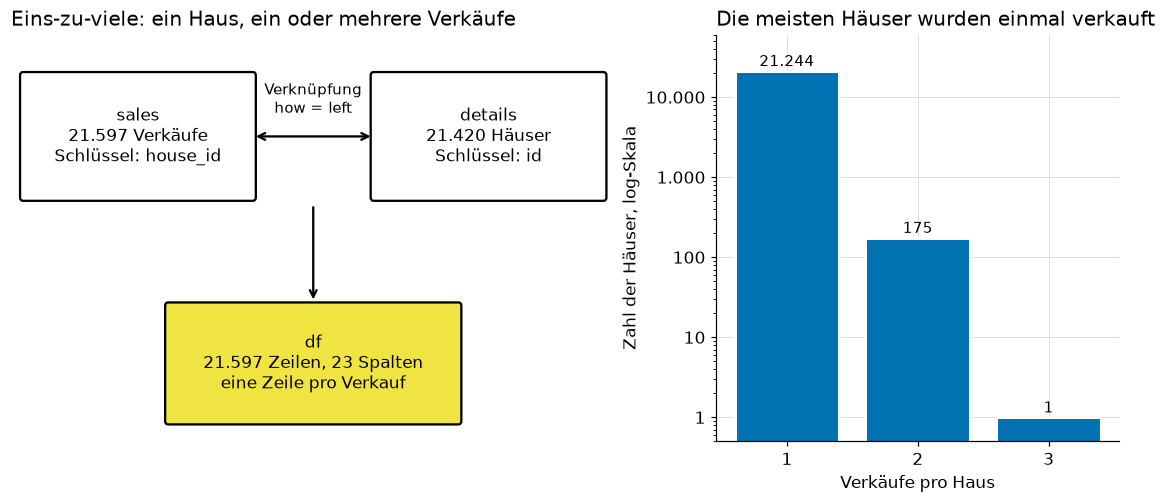

In [3]:
# Bild 1: Eins-zu-viele-Verknüpfung von sales und details
verkaeufe_pro_haus = sales["house_id"].value_counts().value_counts().sort_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
ax1.set_axis_off(); ax1.set_xlim(0, 10); ax1.set_ylim(0, 6)

def kasten(ax, x, y, b, h, text, farbe="white", rand="black"):
    ax.add_patch(FancyBboxPatch((x, y), b, h, boxstyle="round,pad=0.05", fc=farbe, ec=rand, lw=1.5))
    ax.text(x + b / 2, y + h / 2, text, ha="center", va="center", fontsize=11)

kasten(ax1, 0.2, 3.6, 3.8, 1.8, f"sales\n{de_zahl(len(sales))} Verkäufe\nSchlüssel: house_id")
kasten(ax1, 6.0, 3.6, 3.8, 1.8, f"details\n{de_zahl(len(details))} Häuser\nSchlüssel: id")
kasten(ax1, 2.6, 0.3, 4.8, 1.7, f"df\n{de_zahl(len(df))} Zeilen, {df.shape[1]} Spalten\neine Zeile pro Verkauf", farbe=FARBE["fehlend"])
ax1.annotate("", xy=(6.0, 4.5), xytext=(4.0, 4.5), arrowprops=dict(arrowstyle="<->", lw=1.5))
ax1.text(5.0, 4.85, "Verknüpfung\nhow = left", ha="center", fontsize=10)
ax1.annotate("", xy=(5.0, 2.05), xytext=(5.0, 3.5), arrowprops=dict(arrowstyle="->", lw=1.5))
ax1.set_title("Eins-zu-viele: ein Haus, ein oder mehrere Verkäufe", loc="left")

balken = ax2.bar([str(i) for i in verkaeufe_pro_haus.index], verkaeufe_pro_haus.values,
                 color=FARBE["training"], edgecolor="white", linewidth=2)
ax2.set_yscale("log")
ax2.yaxis.set_major_formatter(de_achse())
for b, wert in zip(balken, verkaeufe_pro_haus.values):
    ax2.text(b.get_x() + b.get_width() / 2, wert * 1.15, de_zahl(wert), ha="center", fontsize=10)
ax2.set_xlabel("Verkäufe pro Haus")
ax2.set_ylabel("Zahl der Häuser, log-Skala")
ax2.set_ylim(0.5, 60000)
ax2.set_title("Die meisten Häuser wurden einmal verkauft", loc="left")
speichern(fig, "01_verknuepfung_eins_zu_viele")

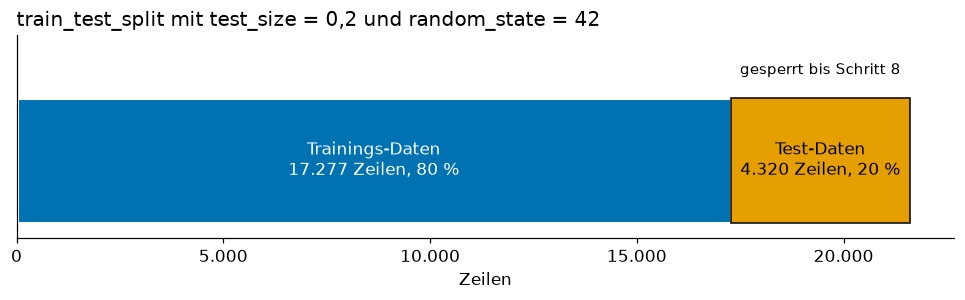

In [4]:
# Bild 2: Aufteilung in Trainings-Daten und Test-Daten
fig, ax = plt.subplots(figsize=(11, 2.4))
n_train, n_test = len(df_train), len(df_test)
ax.barh(0, n_train, color=FARBE["training"], edgecolor="white", linewidth=2)
ax.barh(0, n_test, left=n_train, color=FARBE["test"], edgecolor="black", linewidth=1)
ax.text(n_train / 2, 0, f"Trainings-Daten\n{de_zahl(n_train)} Zeilen, 80 %", ha="center", va="center", color="white", fontsize=11)
ax.text(n_train + n_test / 2, 0, f"Test-Daten\n{de_zahl(n_test)} Zeilen, 20 %", ha="center", va="center", fontsize=11)
ax.text(n_train + n_test / 2, 0.55, "gesperrt bis Schritt 8", ha="center", fontsize=10)
ax.set_yticks([]); ax.set_ylim(-0.5, 0.8)
ax.xaxis.set_major_formatter(de_achse())
ax.set_xlabel("Zeilen")
ax.grid(False)
ax.set_title("train_test_split mit test_size = 0,2 und random_state = 42", loc="left")
speichern(fig, "02_aufteilung_trainings_test")

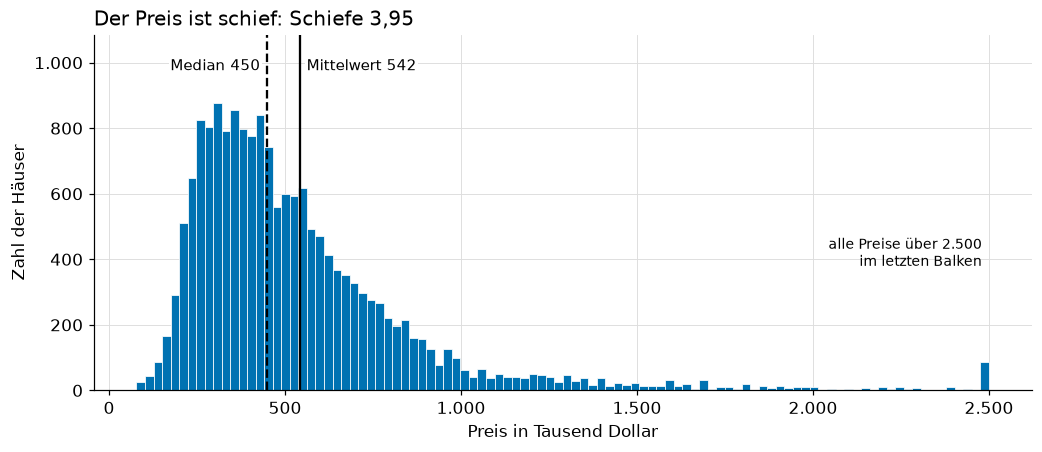

In [5]:
# Bild 3: Verteilung des Preises in den Trainings-Daten
preis_tsd = df_train["price"] / 1000
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.hist(preis_tsd.clip(upper=2500), bins=100, color=FARBE["training"], edgecolor="white", linewidth=0.5)
mittel, median = preis_tsd.mean(), preis_tsd.median()
ax.axvline(median, color=FARBE["text"], linestyle="--", lw=1.5)
ax.axvline(mittel, color=FARBE["text"], lw=1.5)
oben = ax.get_ylim()[1] * 1.18
ax.set_ylim(0, oben)
ax.text(median - 20, oben * 0.9, f"Median {de_zahl(median)}", ha="right", fontsize=10,
        bbox=dict(fc="white", ec="none", pad=1))
ax.text(mittel + 20, oben * 0.9, f"Mittelwert {de_zahl(mittel)}", ha="left", fontsize=10,
        bbox=dict(fc="white", ec="none", pad=1))
ax.text(2480, ax.get_ylim()[1] * 0.35, "alle Preise über 2.500\nim letzten Balken", ha="right", fontsize=9)
ax.xaxis.set_major_formatter(de_achse())
ax.yaxis.set_major_formatter(de_achse())
ax.set_xlabel("Preis in Tausend Dollar")
ax.set_ylabel("Zahl der Häuser")
ax.set_title(f"Der Preis ist schief: Schiefe {de_zahl(df_train['price'].skew(), 2)}", loc="left")
speichern(fig, "03_preis_verteilung")

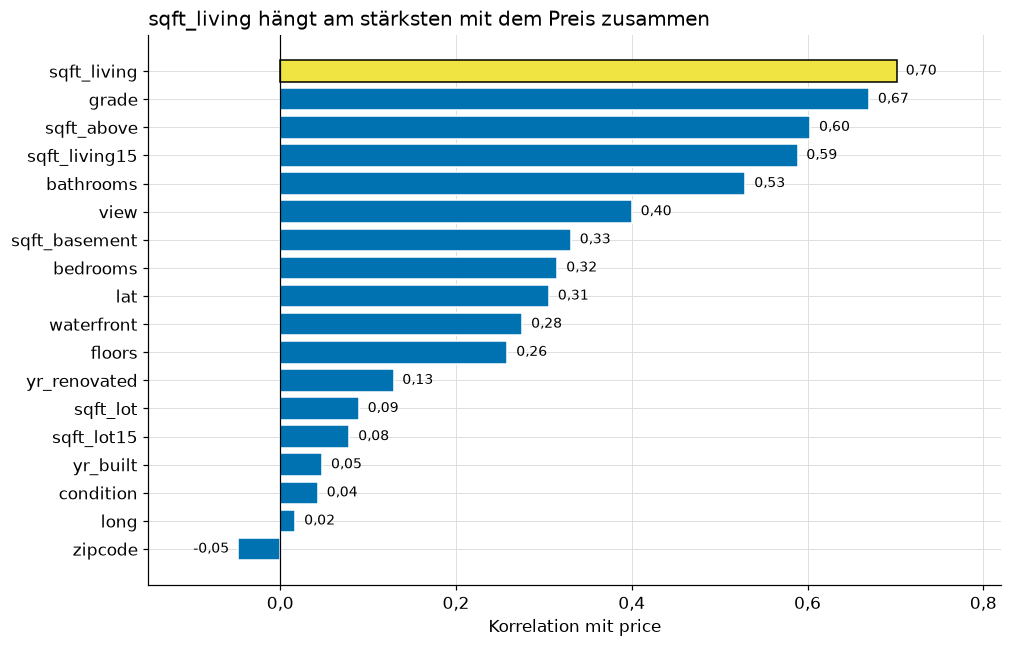

In [6]:
# Bild 4: Korrelation jeder Zahlen-Spalte mit dem Preis
korr = (df_train.drop(columns=["id", "house_id", "id_details", "date"])
        .corr()["price"].drop("price").sort_values())
fig, ax = plt.subplots(figsize=(10, 6.5))
farben = [FARBE["fehlend"] if s == "sqft_living" else FARBE["training"] for s in korr.index]
ax.barh(korr.index, korr.values, color=farben, edgecolor=["black" if s == "sqft_living" else "white" for s in korr.index], linewidth=1)
for i, wert in enumerate(korr.values):
    ax.text(wert + (0.01 if wert >= 0 else -0.01), i, de_zahl(wert, 2), va="center",
            ha="left" if wert >= 0 else "right", fontsize=9)
ax.axvline(0, color=FARBE["text"], lw=0.8)
ax.set_xlim(-0.15, 0.82)
ax.xaxis.set_major_formatter(de_achse(1))
ax.set_xlabel("Korrelation mit price")
ax.set_title("sqft_living hängt am stärksten mit dem Preis zusammen", loc="left")
speichern(fig, "04_korrelation_mit_preis")

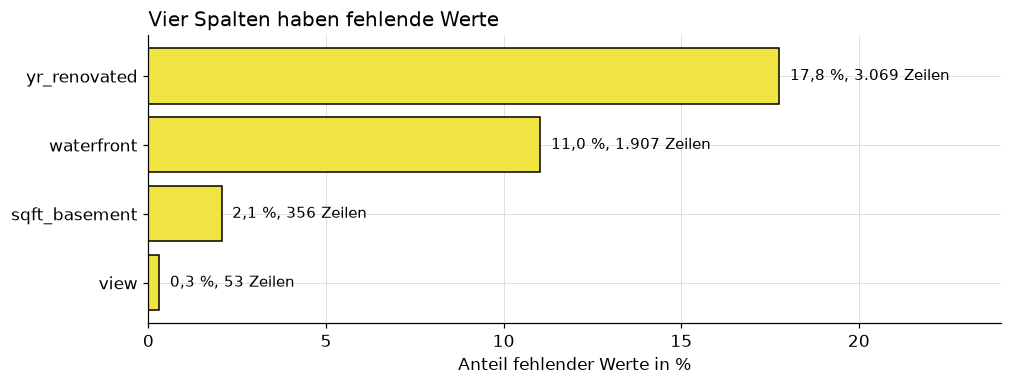

In [7]:
# Bild 5: Fehlende Werte in den Trainings-Daten
fehlend = (df_train.isna().mean() * 100).loc[lambda s: s > 0].sort_values()
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.barh(fehlend.index, fehlend.values, color=FARBE["fehlend"], edgecolor="black", linewidth=1)
for i, (spalte, wert) in enumerate(fehlend.items()):
    ax.text(wert + 0.3, i, f"{de_zahl(wert, 1)} %, {de_zahl(df_train[spalte].isna().sum())} Zeilen", va="center", fontsize=10)
ax.set_xlim(0, 24)
ax.xaxis.set_major_formatter(de_achse())
ax.set_xlabel("Anteil fehlender Werte in %")
ax.set_title("Vier Spalten haben fehlende Werte", loc="left")
speichern(fig, "05_fehlende_werte")

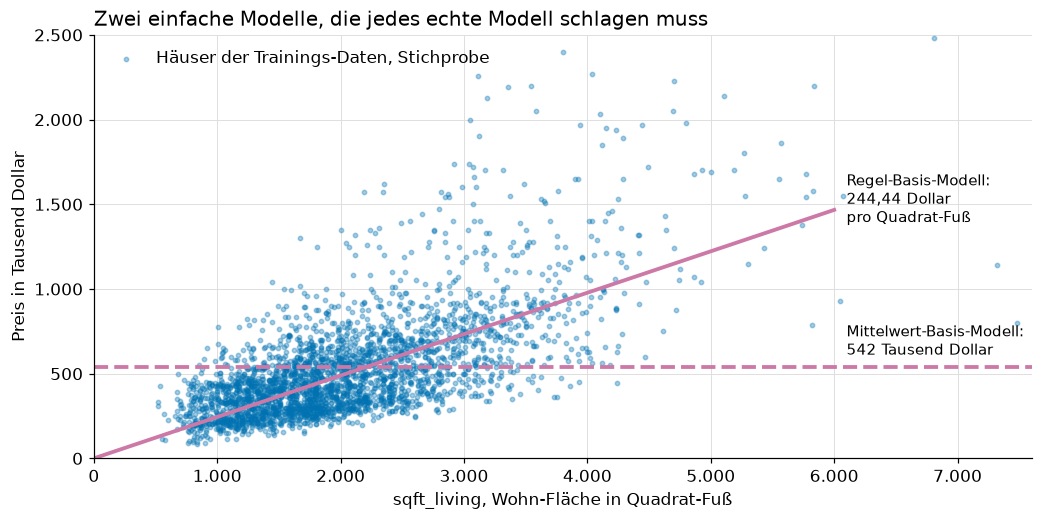

In [8]:
# Bild 6: Die zwei Basis-Modelle
probe = df_train.sample(3000, random_state=0)
fig, ax = plt.subplots(figsize=(11, 5))
ax.scatter(probe["sqft_living"], probe["price"] / 1000, s=8, alpha=0.35, color=FARBE["training"], label="Häuser der Trainings-Daten, Stichprobe")
x = np.linspace(0, 6000, 50)
ax.plot(x, price_per_sqft * x / 1000, color=FARBE["basis"], lw=2.5)
ax.axhline(y_train.mean() / 1000, color=FARBE["basis"], lw=2.5, linestyle="--")
ax.text(6100, price_per_sqft * 6000 / 1000 + 60, f"Regel-Basis-Modell:\n{de_zahl(price_per_sqft, 2)} Dollar\npro Quadrat-Fuß", va="center", fontsize=10)
ax.text(6100, y_train.mean() / 1000 + 40, f"Mittelwert-Basis-Modell:\n{de_zahl(y_train.mean() / 1000)} Tausend Dollar", va="bottom", fontsize=10)
ax.set_xlim(0, 7600); ax.set_ylim(0, 2500)
ax.xaxis.set_major_formatter(de_achse())
ax.yaxis.set_major_formatter(de_achse())
ax.set_xlabel("sqft_living, Wohn-Fläche in Quadrat-Fuß")
ax.set_ylabel("Preis in Tausend Dollar")
ax.legend(loc="upper left", frameon=False)
ax.set_title("Zwei einfache Modelle, die jedes echte Modell schlagen muss", loc="left")
speichern(fig, "06_basis_modelle")

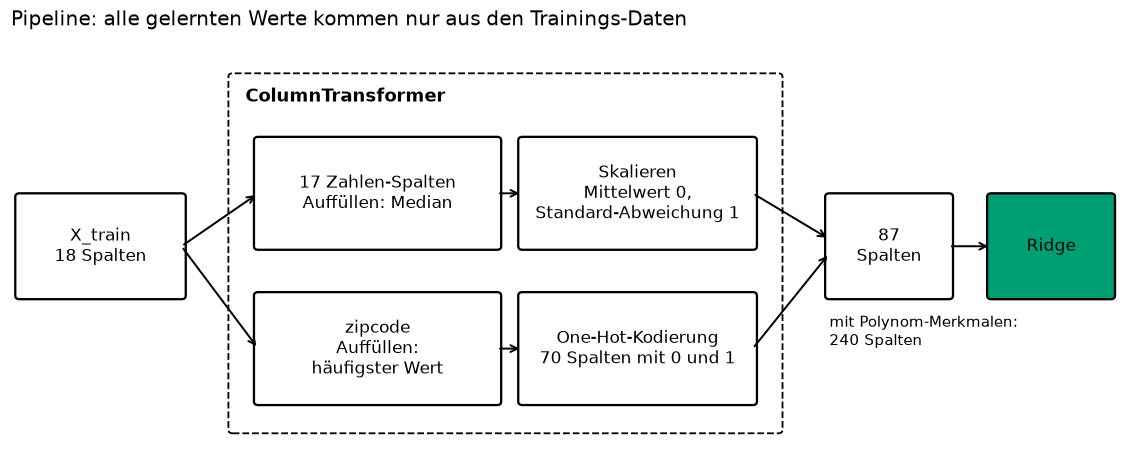

In [9]:
# Bild 7: Aufbau der Pipeline
fig, ax = plt.subplots(figsize=(13, 5))
ax.set_axis_off(); ax.set_xlim(0, 13); ax.set_ylim(0, 6)
kasten(ax, 0.1, 2.3, 1.9, 1.4, f"X_train\n{X_train.shape[1]} Spalten")
ax.add_patch(FancyBboxPatch((2.6, 0.4), 6.4, 5.0, boxstyle="round,pad=0.05", fc="white", ec="black", lw=1.2, linestyle="--"))
ax.text(2.75, 5.05, "ColumnTransformer", fontsize=12, fontweight="bold")
kasten(ax, 2.9, 3.0, 2.8, 1.5, f"{len(num_cols)} Zahlen-Spalten\nAuffüllen: Median")
kasten(ax, 6.0, 3.0, 2.7, 1.5, "Skalieren\nMittelwert 0,\nStandard-Abweichung 1")
kasten(ax, 2.9, 0.8, 2.8, 1.5, "zipcode\nAuffüllen:\nhäufigster Wert")
kasten(ax, 6.0, 0.8, 2.7, 1.5, f"One-Hot-Kodierung\n{df_train['zipcode'].nunique()} Spalten mit 0 und 1")
kasten(ax, 9.6, 2.3, 1.4, 1.4, f"{N_SPALTEN}\nSpalten")
kasten(ax, 11.5, 2.3, 1.4, 1.4, "Ridge", farbe=FARBE["ridge"])
for (x0, y0, x1, y1) in [(2.0, 3.0, 2.9, 3.75), (2.0, 3.0, 2.9, 1.55), (5.7, 3.75, 6.0, 3.75), (5.7, 1.55, 6.0, 1.55),
                         (8.7, 3.75, 9.6, 3.1), (8.7, 1.55, 9.6, 2.9), (11.0, 3.0, 11.5, 3.0)]:
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="->", lw=1.3))
ax.text(9.6, 1.6, f"mit Polynom-Merkmalen:\n{N_SPALTEN_POLY} Spalten", fontsize=10)
ax.set_title("Pipeline: alle gelernten Werte kommen nur aus den Trainings-Daten", loc="left")
speichern(fig, "07_pipeline_aufbau")

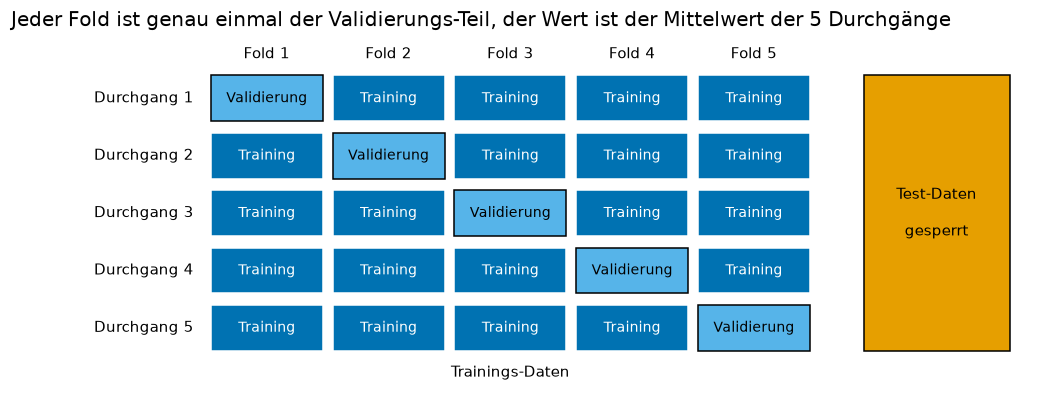

In [10]:
# Bild 8: Kreuz-Validierung mit 5 Folds
fig, ax = plt.subplots(figsize=(12, 4.2))
for durchgang in range(5):
    for fold in range(5):
        ist_val = fold == durchgang
        ax.add_patch(plt.Rectangle((fold * 1.0 + 0.04, 4 - durchgang + 0.1), 0.92, 0.8,
                                   fc=FARBE["validierung"] if ist_val else FARBE["training"],
                                   ec="black" if ist_val else "white", lw=1))
        ax.text(fold + 0.5, 4 - durchgang + 0.5, "Validierung" if ist_val else "Training",
                ha="center", va="center", fontsize=9, color="black" if ist_val else "white")
    ax.text(-0.1, 4 - durchgang + 0.5, f"Durchgang {durchgang + 1}", ha="right", va="center", fontsize=10)
ax.add_patch(plt.Rectangle((5.4, 0.1), 1.2, 4.8, fc=FARBE["test"], ec="black", lw=1))
ax.text(6.0, 2.5, "Test-Daten\n\ngesperrt", ha="center", va="center", fontsize=10)
for fold in range(5):
    ax.text(fold + 0.5, 5.2, f"Fold {fold + 1}", ha="center", fontsize=10)
ax.text(2.5, -0.35, "Trainings-Daten", ha="center", fontsize=10)
ax.set_xlim(-1.6, 6.8); ax.set_ylim(-0.6, 5.6); ax.set_axis_off()
ax.set_title("Jeder Fold ist genau einmal der Validierungs-Teil, der Wert ist der Mittelwert der 5 Durchgänge", loc="left")
speichern(fig, "08_kreuz_validierung")

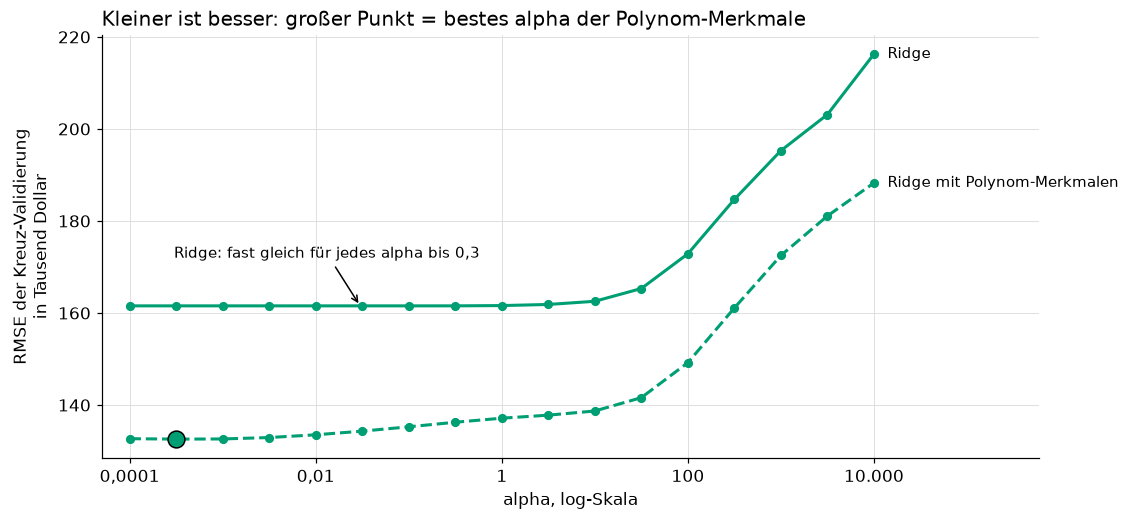

In [11]:
# Bild 9: RMSE der Kreuz-Validierung für verschiedene alpha
alphas = np.logspace(-4, 4, 17)
kurve = {}
for name, modell in [("Ridge", ridge), ("Ridge mit Polynom-Merkmalen", ridge_poly)]:
    kurve[name] = [-cross_val_score(modell.set_params(model__alpha=a), X_train, y_train, cv=cv,
                                    scoring="neg_root_mean_squared_error").mean() for a in alphas]

fig, ax = plt.subplots(figsize=(11, 5))
for (name, werte), stil in zip(kurve.items(), ["-", "--"]):
    ax.plot(alphas, np.array(werte) / 1000, stil, color=FARBE["ridge"], lw=2, marker="o", markersize=5)
    if name != "Ridge":
        i = int(np.argmin(werte))
        ax.plot(alphas[i], werte[i] / 1000, "o", color=FARBE["ridge"], markersize=11, markeredgecolor="black")
    ax.text(alphas[-1] * 1.4, werte[-1] / 1000, name, va="center", fontsize=10)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: de_zahl(x, max(0, int(-np.floor(np.log10(x)))))))
ax.yaxis.set_major_formatter(de_achse())
ax.set_xlim(alphas[0] / 2, alphas[-1] * 60)
ax.set_xlabel("alpha, log-Skala")
ax.set_ylabel("RMSE der Kreuz-Validierung\nin Tausend Dollar")
ax.annotate("Ridge: fast gleich für jedes alpha bis 0,3", xy=(0.03, kurve["Ridge"][5] / 1000), xytext=(0.0003, 172),
            fontsize=10, arrowprops=dict(arrowstyle="->", lw=1))
ax.set_title("Kleiner ist besser: großer Punkt = bestes alpha der Polynom-Merkmale", loc="left")
speichern(fig, "09_alpha_suche")

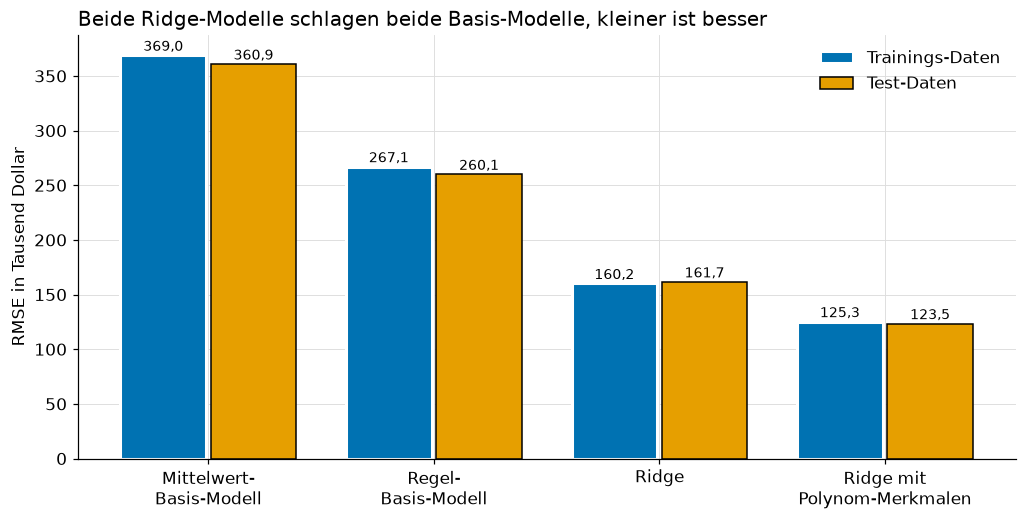

In [12]:
# Bild 10: RMSE aller Modelle auf Trainings-Daten und Test-Daten
modelle = {"Mittelwert-\nBasis-Modell": mean_baseline.predict, "Regel-\nBasis-Modell": rule_baseline,
           "Ridge": best_ridge.predict, "Ridge mit\nPolynom-Merkmalen": best_poly.predict}
train_rmse = [root_mean_squared_error(y_train, f(X_train)) / 1000 for f in modelle.values()]
test_rmse = [root_mean_squared_error(y_test, f(X_test)) / 1000 for f in modelle.values()]
x = np.arange(len(modelle))
fig, ax = plt.subplots(figsize=(11, 5))
b1 = ax.bar(x - 0.2, train_rmse, 0.38, color=FARBE["training"], edgecolor="white", linewidth=2, label="Trainings-Daten")
b2 = ax.bar(x + 0.2, test_rmse, 0.38, color=FARBE["test"], edgecolor="black", linewidth=1, label="Test-Daten")
for balken in (b1, b2):
    for b in balken:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 4, de_zahl(b.get_height(), 1), ha="center", fontsize=9)
ax.set_xticks(x, list(modelle.keys()))
ax.yaxis.set_major_formatter(de_achse())
ax.set_ylabel("RMSE in Tausend Dollar")
ax.legend(frameon=False)
ax.set_title("Beide Ridge-Modelle schlagen beide Basis-Modelle, kleiner ist besser", loc="left")
speichern(fig, "10_modell_vergleich")

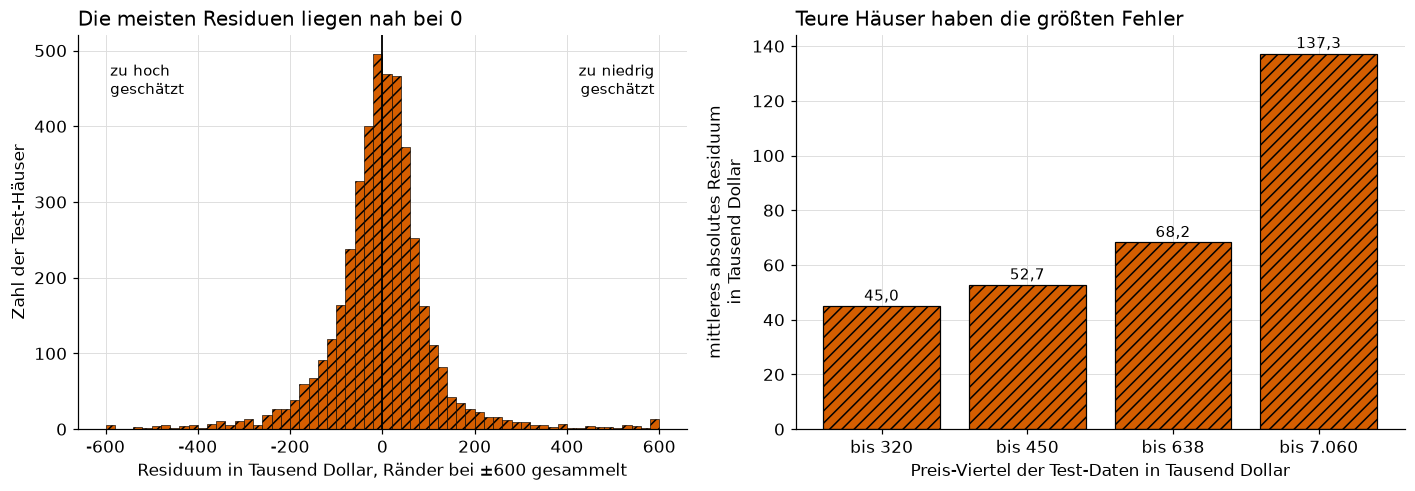

In [13]:
# Bild 11: Residuen des besten Modells auf den Test-Daten
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6))
ax1.hist((residuals / 1000).clip(-600, 600), bins=60, color=FARBE["fehler"], edgecolor="black", linewidth=0.4, hatch=SCHRAFFUR)
ax1.axvline(0, color=FARBE["text"], lw=1.2)
ax1.text(-590, ax1.get_ylim()[1] * 0.85, "zu hoch\ngeschätzt", fontsize=10)
ax1.text(590, ax1.get_ylim()[1] * 0.85, "zu niedrig\ngeschätzt", ha="right", fontsize=10)
ax1.xaxis.set_major_formatter(de_achse())
ax1.yaxis.set_major_formatter(de_achse())
ax1.set_xlabel("Residuum in Tausend Dollar, Ränder bei ±600 gesammelt")
ax1.set_ylabel("Zahl der Test-Häuser")
ax1.set_title("Die meisten Residuen liegen nah bei 0", loc="left")

viertel = residuals.abs().groupby(pd.qcut(y_test, 4)).mean() / 1000
namen = [f"bis {de_zahl(i.right / 1000)}" for i in viertel.index]
balken = ax2.bar(namen, viertel.values, color=FARBE["fehler"], edgecolor="black", linewidth=0.8, hatch=SCHRAFFUR)
for b in balken:
    ax2.text(b.get_x() + b.get_width() / 2, b.get_height() + 2, de_zahl(b.get_height(), 1), ha="center", fontsize=10)
ax2.yaxis.set_major_formatter(de_achse())
ax2.set_xlabel("Preis-Viertel der Test-Daten in Tausend Dollar")
ax2.set_ylabel("mittleres absolutes Residuum\nin Tausend Dollar")
ax2.set_title("Teure Häuser haben die größten Fehler", loc="left")
fig.tight_layout()
speichern(fig, "11_residuen")

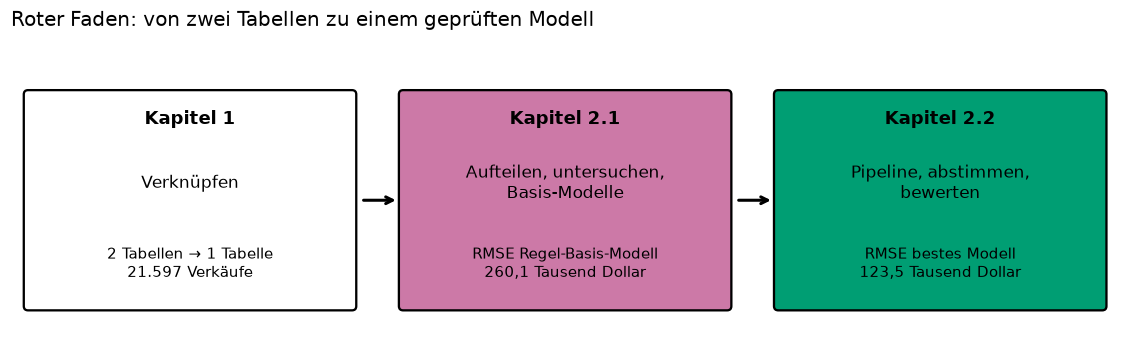

In [14]:
# Bild 12: Der rote Faden des Kurses
fig, ax = plt.subplots(figsize=(13, 3.6))
ax.set_axis_off(); ax.set_xlim(0, 13); ax.set_ylim(0, 3.6)
stationen = [
    ("Kapitel 1", "Verknüpfen", f"2 Tabellen → 1 Tabelle\n{de_zahl(len(df))} Verkäufe", "white"),
    ("Kapitel 2.1", "Aufteilen, untersuchen,\nBasis-Modelle", f"RMSE Regel-Basis-Modell\n{de_zahl(root_mean_squared_error(y_test, rule_baseline(X_test)) / 1000, 1)} Tausend Dollar", FARBE["basis"]),
    ("Kapitel 2.2", "Pipeline, abstimmen,\nbewerten", f"RMSE bestes Modell\n{de_zahl(root_mean_squared_error(y_test, best_poly.predict(X_test)) / 1000, 1)} Tausend Dollar", FARBE["ridge"]),
]
for i, (kap, titel, zahl, farbe) in enumerate(stationen):
    x0 = 0.2 + i * 4.4
    kasten(ax, x0, 0.4, 3.8, 2.5, "", farbe=farbe)
    ax.text(x0 + 1.9, 2.55, kap, ha="center", fontsize=12, fontweight="bold")
    ax.text(x0 + 1.9, 1.85, titel, ha="center", va="center", fontsize=11)
    ax.text(x0 + 1.9, 0.9, zahl, ha="center", va="center", fontsize=10)
    if i < 2:
        ax.annotate("", xy=(x0 + 4.35, 1.65), xytext=(x0 + 3.9, 1.65), arrowprops=dict(arrowstyle="->", lw=2))
ax.set_title("Roter Faden: von zwei Tabellen zu einem geprüften Modell", loc="left")
speichern(fig, "12_roter_faden")